# Assignment 3

In [ ]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_diabetes, load_breast_cancer, load_iris, load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score, accuracy_score,
    precision_score, recall_score, f1_score, roc_auc_score,
    silhouette_score, adjusted_rand_score, davies_bouldin_score
)

## Compare regression models with MAE, RMSE, and R-squared


3(a) Regression model evaluation
            Model  MAE (lower better)  RMSE (lower better)  R2 (higher better)
Linear Regression              41.549               53.370               0.485
            Ridge              41.507               53.318               0.486
            Lasso              41.485               53.282               0.487


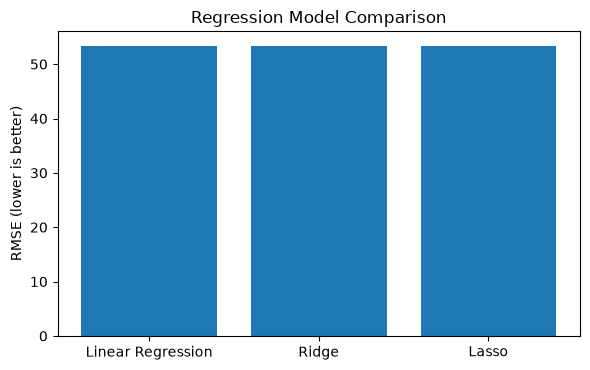

In [3]:
print("\n3(a) Regression model evaluation")
diabetes = load_diabetes()
X_train, X_test, y_train, y_test = train_test_split(
    diabetes.data, diabetes.target, test_size=0.25, random_state=42
)
regression_models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.1, max_iter=10000),
}
regression_rows = []
for name, estimator in regression_models.items():
    model = make_pipeline(StandardScaler(), estimator)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    regression_rows.append({
        "Model": name,
        "MAE (lower better)": mean_absolute_error(y_test, pred),
        "RMSE (lower better)": np.sqrt(mean_squared_error(y_test, pred)),
        "R2 (higher better)": r2_score(y_test, pred),
    })
regression_results = pd.DataFrame(regression_rows).round(3)
print(regression_results.to_string(index=False))
plt.figure(figsize=(6, 3.8))
plt.bar(regression_results["Model"], regression_results["RMSE (lower better)"])
plt.ylabel("RMSE (lower is better)")
plt.title("Regression Model Comparison")
plt.tight_layout()
plt.show()

## Compare classification models on one held-out test set


3(b) Classification model evaluation
                  Model  Accuracy  Precision (malignant)  Recall (malignant)  F1 (malignant)  ROC-AUC
          Logistic - L2     0.965                  0.980               0.925           0.951    0.996
          Logistic - L1     0.965                  0.980               0.925           0.951    0.997
      Gradient Boosting     0.965                  1.000               0.906           0.950    0.995
              KNN (k=5)     0.958                  0.980               0.906           0.941    0.986
          Random Forest     0.958                  1.000               0.887           0.940    0.995
   Gaussian Naive Bayes     0.944                  1.000               0.849           0.918    0.995
Decision Tree - Entropy     0.923                  0.957               0.830           0.889    0.945
   Decision Tree - Gini     0.895                  0.975               0.736           0.839    0.934


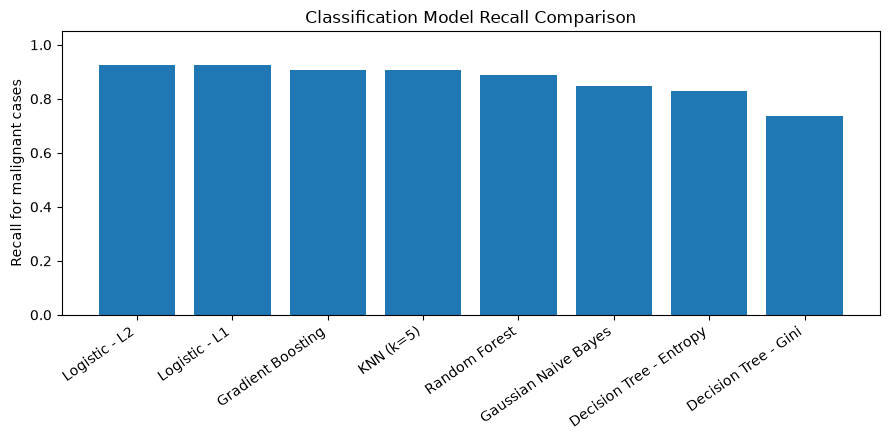

In [5]:
print("\n3(b) Classification model evaluation")
cancer = load_breast_cancer()
X = cancer.data
y = (cancer.target == 0).astype(int)  # 1 = malignant, so recall measures malignant cases found
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
def logistic_estimator(penalty):
    # Compatible with older scikit-learn and the newer l1_ratio API.
    if LogisticRegression().get_params().get("penalty") == "deprecated":
        if penalty == "l1":
            return LogisticRegression(l1_ratio=1.0, C=1.0, solver="saga", max_iter=5000, random_state=42)
        return LogisticRegression(l1_ratio=0.0, C=1.0, solver="lbfgs", max_iter=3000, random_state=42)
    return LogisticRegression(penalty=penalty, C=1.0, solver="liblinear", max_iter=3000, random_state=42)

classification_models = {
    "Decision Tree - Gini": DecisionTreeClassifier(criterion="gini", max_depth=4, random_state=42),
    "Decision Tree - Entropy": DecisionTreeClassifier(criterion="entropy", max_depth=4, random_state=42),
    "Logistic - L2": make_pipeline(StandardScaler(), logistic_estimator("l2")),
    "Logistic - L1": make_pipeline(StandardScaler(), logistic_estimator("l1")) ,
    "KNN (k=5)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Gaussian Naive Bayes": GaussianNB(),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_features="sqrt", random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42),
}
classification_rows = []
for name, model in classification_models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    if hasattr(model, "predict_proba"):
        probabilities = model.predict_proba(X_test)[:, 1]
    else:
        probabilities = None
    classification_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (malignant)": precision_score(y_test, pred, zero_division=0),
        "Recall (malignant)": recall_score(y_test, pred, zero_division=0),
        "F1 (malignant)": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities) if probabilities is not None else np.nan,
    })
classification_results = pd.DataFrame(classification_rows).round(3).sort_values("F1 (malignant)", ascending=False)
print(classification_results.to_string(index=False))
plt.figure(figsize=(9, 4.5))
plt.bar(classification_results["Model"], classification_results["Recall (malignant)"])
plt.ylim(0, 1.05)
plt.ylabel("Recall for malignant cases")
plt.title("Classification Model Recall Comparison")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

## Compare clustering models with silhouette, Davies-Bouldin, and adjusted Rand index


3(c) Clustering model evaluation
              Model  Silhouette (higher better)  Davies-Bouldin (lower better)  ARI vs known classes (higher better)
            K-means                       0.460                          0.834                                 0.620
Hierarchical (Ward)                       0.447                          0.803                                 0.615
   Gaussian Mixture                       0.374                          1.081                                 0.904


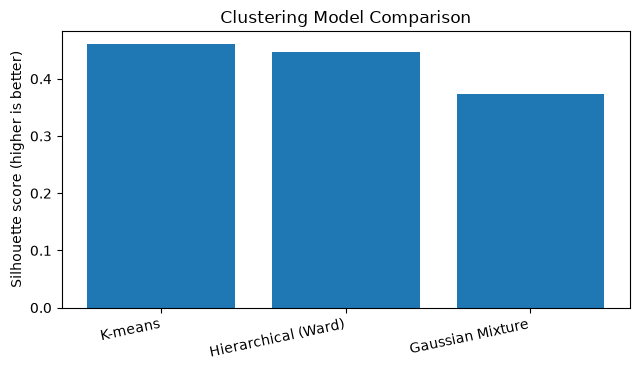

In [6]:
print("\n3(c) Clustering model evaluation")
iris = load_iris()
X_scaled = StandardScaler().fit_transform(iris.data)
clustering_models = {
    "K-means": KMeans(n_clusters=3, n_init=10, random_state=42),
    "Hierarchical (Ward)": AgglomerativeClustering(n_clusters=3, linkage="ward"),
    "Gaussian Mixture": GaussianMixture(n_components=3, covariance_type="full", n_init=5, random_state=42),
}
cluster_rows = []
for name, model in clustering_models.items():
    labels = model.fit_predict(X_scaled)
    cluster_rows.append({
        "Model": name,
        "Silhouette (higher better)": silhouette_score(X_scaled, labels),
        "Davies-Bouldin (lower better)": davies_bouldin_score(X_scaled, labels),
        "ARI vs known classes (higher better)": adjusted_rand_score(iris.target, labels),
    })
cluster_results = pd.DataFrame(cluster_rows).round(3)
print(cluster_results.to_string(index=False))
plt.figure(figsize=(6.5, 3.8))
plt.bar(cluster_results["Model"], cluster_results["Silhouette (higher better)"])
plt.ylabel("Silhouette score (higher is better)")
plt.title("Clustering Model Comparison")
plt.xticks(rotation=12, ha="right")
plt.tight_layout()
plt.show()

## Evaluate PCA by the amount of variation retained


3(d) PCA evaluation
PC1 variance: 0.362
PC2 variance: 0.192
Total variance kept by two components: 0.554


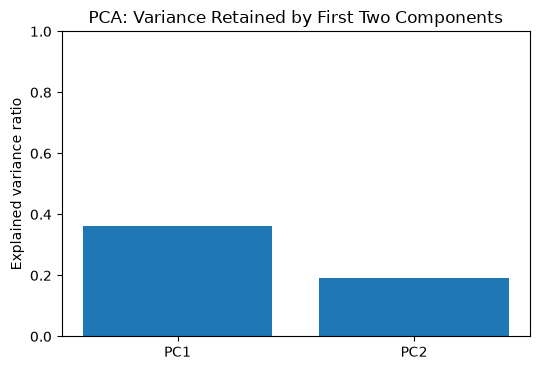

In [7]:
print("\n3(d) PCA evaluation")
wine = load_wine()
X_scaled = StandardScaler().fit_transform(wine.data)
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_scaled)
variance = pca.explained_variance_ratio_
print(f"PC1 variance: {variance[0]:.3f}")
print(f"PC2 variance: {variance[1]:.3f}")
print(f"Total variance kept by two components: {variance.sum():.3f}")
plt.figure(figsize=(5.5, 3.8))
plt.bar(["PC1", "PC2"], variance)
plt.ylim(0, 1)
plt.ylabel("Explained variance ratio")
plt.title("PCA: Variance Retained by First Two Components")
plt.tight_layout()
plt.show()
